In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.preprocessing import MinMaxScaler

In [2]:
my_movies=pd.read_csv("my_movies.csv")
my_movies

,movie_id,title,original_title,release_year,director,genres,title_key,production_country,synopsis,languages,paises_norm,decade,synopsis_length,synopsis_words
0,tt0000009,Miss Jerry,Miss Jerry,1894.0,Alexander Black,Romance,miss jerry,United States of America,After finding out that her father is suffering...,Silent film,United States,1890.0,371.0,64.0
1,tt0000147,The Corbett-Fitzsimmons Fight,The Corbett-Fitzsimmons Fight,1897.0,Enoch J. Rector,"Documentary,News,Sport",the corbett-fitzsimmons fight,NaN,The film no longer exists in its entirety; how...,NaN,NaN,1890.0,1190.0,195.0
2,tt0000502,Bohemios,Bohemios,1905.0,Ricardo de Baños,NaN,bohemios,NaN,NaN,NaN,NaN,1900.0,NaN,NaN
3,tt0000574,The Story of the Kelly Gang,The Story of the Kelly Gang,1906.0,Charles Tait,"Action,Adventure,Biography",the story of the kelly gang,Australia,The Story of the Kelly Gangs tone is of sorrow...,English Language,Australia,1900.0,1660.0,271.0
4,tt0000591,The Prodigal Son,L'enfant prodigue,1907.0,Michel Carré,Drama,the prodigal son,NaN,NaN,NaN,NaN,1900.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
759690,tt9916622,Rodolpho Teóphilo - O Legado de um Pioneiro,Rodolpho Teóphilo - O Legado de um Pioneiro,2015.0,NaN,Documentary,rodolpho teóphilo - o legado de um pioneiro,NaN,NaN,NaN,NaN,2010.0,NaN,NaN
759691,tt9916680,De la ilusión al desconcierto: cine colombiano...,De la ilusión al desconcierto: cine colombiano...,2007.0,Luis Ospina,Documentary,de la ilusión al desconcierto: cine colombiano...,NaN,NaN,NaN,NaN,2000.0,NaN,NaN
759692,tt9916706,Dankyavar Danka,Dankyavar Danka,2013.0,Kanchan Nayak,Comedy,dankyavar danka,NaN,NaN,NaN,NaN,2010.0,NaN,NaN
759693,tt9916730,6 Gunn,6 Gunn,2017.0,Kiran Gawade,Drama,6 gunn,NaN,NaN,NaN,NaN,2010.0,NaN,NaN


In [3]:
directores_espanoles = ["Luis García Berlanga","Carlos Saura","Luis Buñuel","Pedro Almodóvar","Víctor Erice","Mario Camus",\
                        "José Luis Garci","Vicente Aranda","Pilar Miró","Juan Antonio Bardem","Fernando Fernán Gómez",\
                        "Jaime de Armiñán","Bigas Luna","José Luis Borau","Manuel Gutiérrez Aragón","Jaime Chávarri",\
                        "José Luis Cuerda","Angelino Fons","Fernando Trueba","Fernando Colomo","Francesc Betriu","Eloy de la Iglesia",\
                        "José Antonio de la Loma","Iván Zulueta","Narciso Ibáñez Serrador","Jesús Franco","Juan Piquer Simón",\
                        "Imanol Uribe","Montxo Armendáriz","Pere Portabella"]

mascara = (
    my_movies["director"].isin(directores_espanoles) &
    (
        my_movies["paises_norm"].isna() |
        (my_movies["paises_norm"].str.strip() == "")
    )
)

my_movies.loc[mascara, "paises_norm"] = "Spain"
my_movies.loc[mascara, "production_country"] = "Spain"

In [4]:
my_movies[my_movies["director"]=="Eloy de la Iglesia"]

,movie_id,title,original_title,release_year,director,genres,title_key,production_country,synopsis,languages,paises_norm,decade,synopsis_length,synopsis_words
44005,tt0060398,Fantasía... 3,Fantasía... 3,1966.0,Eloy de la Iglesia,Fantasy,fantasía... 3,Spain,NaN,NaN,Spain,1960.0,NaN,NaN
45587,tt0062648,Algo amargo en la boca,Algo amargo en la boca,1969.0,Eloy de la Iglesia,Drama,algo amargo en la boca,Spain,NaN,NaN,Spain,1960.0,NaN,NaN
47753,tt0065601,Cuadrilátero,Cuadrilátero,1970.0,Eloy de la Iglesia,"Drama,Sport",cuadrilátero,Spain,NaN,Spanish Language,Spain,1970.0,NaN,NaN
49312,tt0067732,The Cannibal Man,La semana del asesino,1972.0,Eloy de la Iglesia,"Crime,Drama,Horror",the cannibal man,Spain,NaN,NaN,Spain,1970.0,NaN,NaN
49389,tt0067836,The Glass Ceiling,El techo de cristal,1971.0,Eloy de la Iglesia,"Drama,Horror,Mystery",the glass ceiling,Spain,NaN,NaN,Spain,1970.0,NaN,NaN
50957,tt0070126,Murder in a Blue World,Una gota de sangre para morir amando,1973.0,Eloy de la Iglesia,"Crime,Drama,Horror",murder in a blue world,Spain,"Anna Vernia, a beautiful young nurse, receives...",NaN,Spain,1970.0,3768.0,667.0
51183,tt0070432,No One Heard the Scream,Nadie oyó gritar,1973.0,Eloy de la Iglesia,"Horror,Thriller",no one heard the scream,Spain,NaN,NaN,Spain,1970.0,NaN,NaN
53083,tt0073218,Forbidden Love Game,Juego de amor prohibido,1975.0,Eloy de la Iglesia,"Crime,Drama,Thriller",forbidden love game,Spain,NaN,NaN,Spain,1970.0,NaN,NaN
54313,tt0075027,The Other Bedroom,La otra alcoba,1976.0,Eloy de la Iglesia,"Comedy,Drama",the other bedroom,Spain,NaN,NaN,Spain,1970.0,NaN,NaN
54345,tt0075069,Hidden Pleasures,Los placeres ocultos,1977.0,Eloy de la Iglesia,Drama,hidden pleasures,Spain,"Eduardo, a well off bank manager in his fortie...",Spanish Language,Spain,1970.0,2867.0,497.0


In [5]:
my_movies["release_year"] = my_movies["release_year"].astype("Int64")
peliculas_periodo = my_movies[my_movies["release_year"].between(1961,1989)]
peliculas_periodo

,movie_id,title,original_title,release_year,director,genres,title_key,production_country,synopsis,languages,paises_norm,decade,synopsis_length,synopsis_words
25283,tt0036574,"January 30, 1945",Der 30. Januar 1945,1965,NaN,Documentary,"january 30, 1945",NaN,NaN,NaN,NaN,1960.0,NaN,NaN
25312,tt0036606,"Another Time, Another Place","Another Time, Another Place",1983,Michael Radford,"Drama,War","another time, another place",NaN,NaN,NaN,NaN,1980.0,NaN,NaN
27605,tt0039442,"Habla, mudita","Habla, mudita",1973,Manuel Gutiérrez Aragón,Drama,"habla, mudita",Spain,NaN,NaN,Spain,1970.0,NaN,NaN
28023,tt0039965,Viva Chihuahua,Viva Chihuahua,1961,Gilberto Martínez Solares,"Comedy,Western",viva chihuahua,NaN,NaN,NaN,NaN,1960.0,NaN,NaN
29849,tt0042423,The Dungeon of Harrow,The Dungeon of Harrow,1964,Pat Boyette,Horror,the dungeon of harrow,NaN,NaN,NaN,NaN,1960.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
759624,tt9913320,Seitô seihanzai,Seitô seihanzai,1981,Satoru Kobayashi,NaN,seitô seihanzai,NaN,NaN,NaN,NaN,1980.0,NaN,NaN
759630,tt9913814,Chikan densha: Muremure shanai,Chikan densha: Muremure shanai,1981,Minoru Inao,NaN,chikan densha: muremure shanai,NaN,NaN,NaN,NaN,1980.0,NaN,NaN
759631,tt9913834,Hiniku: Nure nawazeme,Hiniku: Nure nawazeme,1981,Kaoru Umezawa,NaN,hiniku: nure nawazeme,NaN,NaN,NaN,NaN,1980.0,NaN,NaN
759633,tt9913878,Document porno: Yubi ijime,Document porno: Yubi ijime,1981,Kôji Kamoda,NaN,document porno: yubi ijime,NaN,NaN,NaN,NaN,1980.0,NaN,NaN


In [6]:
peliculas_periodo=peliculas_periodo[peliculas_periodo["paises_norm"].isin(["Spain"])]
peliculas_periodo

,movie_id,title,original_title,release_year,director,genres,title_key,production_country,synopsis,languages,paises_norm,decade,synopsis_length,synopsis_words
27605,tt0039442,"Habla, mudita","Habla, mudita",1973,Manuel Gutiérrez Aragón,Drama,"habla, mudita",Spain,NaN,NaN,Spain,1970.0,NaN,NaN
39600,tt0054717,Canción de juventud,Canción de juventud,1962,Luis Lucia,"Comedy,Musical",canción de juventud,Spain,Rocio is an orphan girl who is in a finishing ...,Spanish Language,Spain,1960.0,396.0,80.0
40118,tt0055310,Placido,Plácido,1961,Luis García Berlanga,"Comedy,Drama",placido,Spain,NaN,NaN,Spain,1960.0,NaN,NaN
40357,tt0055588,La venganza de Don Mendo,La venganza de Don Mendo,1962,Fernando Fernán Gómez,Comedy,la venganza de don mendo,Spain,NaN,NaN,Spain,1960.0,NaN,NaN
40366,tt0055601,Viridiana,Viridiana,1961,Luis Buñuel,Drama,viridiana,Spain,NaN,NaN,Spain,1960.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
426448,tt2342037,Claire,Claire,1983,Jesús Franco,"Adult,Comedy,Drama",claire,Spain,NaN,NaN,Spain,1980.0,NaN,NaN
535650,tt3452710,The Sadist of Notre Dame,El sádico de Notre-Dame,1979,Jesús Franco,Horror,the sadist of notre dame,Spain,NaN,NaN,Spain,1970.0,NaN,NaN
536786,tt3463298,Sexorcismes,Sexorcismes,1975,Jesús Franco,"Adult,Horror",sexorcismes,Spain,NaN,NaN,Spain,1970.0,NaN,NaN
622778,tt43616539,"Run, Blancanieves, Run","Run, Blancanieves, Run",1967,Jaime Chávarri,NaN,"run, blancanieves, run",Spain,NaN,NaN,Spain,1960.0,NaN,NaN


In [7]:
peliculas_periodo[peliculas_periodo["director"]=="Pedro Almodóvar"]

,movie_id,title,original_title,release_year,director,genres,title_key,production_country,synopsis,languages,paises_norm,decade,synopsis_length,synopsis_words
58547,tt0081323,"Pepi, Luci, Bom and Other Girls Like Mom","Pepi, Luci, Bom y otras chicas del montón",1980,Pedro Almodóvar,Comedy,"pepi, luci, bom and other girls like mom",Spain,NaN,NaN,Spain,1980.0,NaN,NaN
60497,tt0084228,Labyrinth of Passion,Laberinto de pasiones,1982,Pedro Almodóvar,"Comedy,Drama,Romance",labyrinth of passion,Spain,NaN,NaN,Spain,1980.0,NaN,NaN
61316,tt0085496,Dark Habits,Entre tinieblas,1983,Pedro Almodóvar,"Comedy,Drama",dark habits,Spain,NaN,NaN,Spain,1980.0,NaN,NaN
63306,tt0088461,What Have I Done to Deserve This?,¿Qué he hecho YO para merecer esto!!,1984,Pedro Almodóvar,"Comedy,Drama",what have i done to deserve this?,Spain,The film is a slice of a housewife's life in 1...,"English Language, Spanish Language",Spain,1980.0,1058.0,170.0
65189,tt0091495,Matador,Matador,1986,Pedro Almodóvar,"Drama,Thriller",matador,Spain,NaN,NaN,Spain,1980.0,NaN,NaN
66421,tt0093412,Law of Desire,La ley del deseo,1987,Pedro Almodóvar,"Comedy,Drama,Thriller",law of desire,Spain,NaN,NaN,Spain,1980.0,NaN,NaN
67883,tt0095675,Women on the Verge of a Nervous Breakdown,"Mujeres al borde de un ataque de ""nervios""",1988,Pedro Almodóvar,"Comedy,Drama",women on the verge of a nervous breakdown,Spain,NaN,NaN,Spain,1980.0,NaN,NaN
71226,tt0101026,Tie Me Up! Tie Me Down!,Átame!,1989,Pedro Almodóvar,"Comedy,Crime,Drama",tie me up! tie me down!,Spain,NaN,NaN,Spain,1980.0,NaN,NaN
103566,tt0167941,Folle... folle... fólleme Tim!,Folle... folle... fólleme Tim!,1978,Pedro Almodóvar,Comedy,folle... folle... fólleme tim!,Spain,NaN,NaN,Spain,1970.0,NaN,NaN


In [8]:
df_actividad_femenina_esp = pd.DataFrame({
    "year": [
        1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 
        1970, 1971, 1972, 1973, 1974, 1975, 1976, 1977, 1978, 
        1979, 1980, 1981, 1982, 1983, 1984, 1985, 1986, 1987, 
        1988, 1989
    ],
    "female_activity_rate": [
        18.3, 18.5, 18.8, 19.0, 19.2, 19.4, 19.5, 19.5, 19.6,
        19.6, 20.1, 20.8, 21.5, 22.3, 23.1, 28.5, 27.8, 27.7,
        27.6, 27.2, 26.8, 27.2, 27.8, 27.7, 27.8, 28.5, 31.1,
        32.5, 32.8
    ]
})
df_actividad_femenina_esp

,year,female_activity_rate
0,1961,18.3
1,1962,18.5
2,1963,18.8
3,1964,19.0
4,1965,19.2
5,1966,19.4
6,1967,19.5
7,1968,19.5
8,1969,19.6
9,1970,19.6


In [9]:
df_consumo_drogas_esp = pd.DataFrame({
    "periodo": [
        "1961-1974", "1961-1974", 
        "1975-1981", "1975-1981", 
        "1982-1989", "1982-1989"
    ],
    "gender": [
        "Men", "Women", 
        "Men", "Women", 
        "Men", "Women"
    ],
    "cannabis": [1.5, 0.2, 12.0, 4.5, 18.0, 7.5],
    "cocaine":  [0.1, 0.0, 0.8,  0.3, 3.5,  1.2],
    "heroin":   [0.0, 0.0, 1.2,  0.4, 2.5,  0.8],
    "anfetaminas": [4.0, 6.0, 5.5,  4.0, 3.0,  2.0]
})
df_consumo_drogas_esp

,periodo,gender,cannabis,cocaine,heroin,anfetaminas
0,1961-1974,Men,1.5,0.1,0.0,4.0
1,1961-1974,Women,0.2,0.0,0.0,6.0
2,1975-1981,Men,12.0,0.8,1.2,5.5
3,1975-1981,Women,4.5,0.3,0.4,4.0
4,1982-1989,Men,18.0,3.5,2.5,3.0
5,1982-1989,Women,7.5,1.2,0.8,2.0


In [10]:
df_divorcios_esp = pd.DataFrame({
    "year": [
        1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969,
        1970, 1971, 1972, 1973, 1974, 1975, 1976, 1977, 1978,
        1979, 1980, 1981, 1982, 1983, 1984, 1985, 1986, 1987,
        1988, 1989
    ],
    "divorce_rate_per_1000": [
        0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
        0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
        0.0, 0.0, 0.3, 0.6, 0.5, 0.5, 0.5, 0.5, 0.5,
        0.6, 0.6
    ]
})
df_divorcios_esp

,year,divorce_rate_per_1000
0,1961,0.0
1,1962,0.0
2,1963,0.0
3,1964,0.0
4,1965,0.0
5,1966,0.0
6,1967,0.0
7,1968,0.0
8,1969,0.0
9,1970,0.0


In [11]:
df_peliculas_anio = (peliculas_periodo.groupby("release_year").size().reset_index(name="peliculas_producidas"))

df_actividad_renamed = df_actividad_femenina_esp.rename(columns={"year": "release_year"})
df_divorcios_renamed = df_divorcios_esp.rename(columns={"year": "release_year"})

df_social_anual = df_actividad_renamed.merge(df_divorcios_renamed, on="release_year")
df_social_anual = df_social_anual.merge(df_peliculas_anio, on="release_year", how="left").fillna(0)

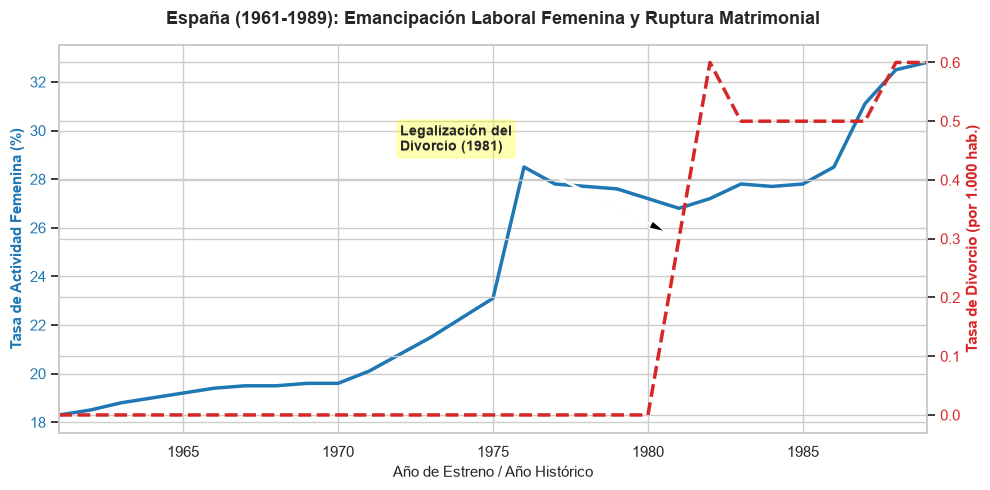

In [ ]:
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 10, "axes.labelsize": 11})

fig, ax1 = plt.subplots(figsize=(10, 5))

color = "#1f77b4"
ax1.set_xlabel("Año de Estreno / Año Histórico")
ax1.set_ylabel("Tasa de Actividad Femenina (%)", color=color, fontweight="bold")
line1 = ax1.plot(
    df_social_anual["release_year"],
    df_social_anual["female_activity_rate"],
    color=color,
    linewidth=2.5,
    label="Actividad Femenina",
)
ax1.tick_params(axis="y", labelcolor=color)
ax1.set_xlim(1961, 1989)

ax2 = ax1.twinx()
color = "#d62728"
ax2.set_ylabel("Tasa de Divorcio (por 1.000 hab.)", color=color, fontweight="bold")
line2 = ax2.plot(
    df_social_anual["release_year"],
    df_social_anual["divorce_rate_per_1000"],
    color=color,
    linewidth=2.5,
    linestyle="--",
    label="Tasa Divorcio (Ley 1981)",
)
ax2.tick_params(axis="y", labelcolor=color)

ax2.annotate(
    "Legalización del\nDivorcio (1981)",
    xy=(1981, 0.3),
    xytext=(1972, 0.45),
    arrowprops=dict(facecolor="black", shrink=0.08, width=1, headwidth=6),
    fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.3),
)

plt.title(
    "España (1961-1989): Emancipación Laboral Femenina y Ruptura Matrimonial",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
plt.tight_layout()
plt.show()

In [ ]:
df_peliculas = pd.read_csv("peliculas_1961_1989_clasificado.csv").copy()

df_peliculas["release_year"] = pd.to_numeric(df_peliculas["release_year"], errors="coerce")

df_peliculas = df_peliculas.dropna(subset=["release_year"])

df_peliculas["release_year"] = (df_peliculas["release_year"].astype(int))

variables_cine = [
    "drug_score",
    "women_empowerment_score",
    "family_tradition_score",
    "sexual_freedom_score",
    "political_repression_score"
]

df_cine_anual = (
    df_peliculas
    .groupby("release_year")
    .agg(
        **{
            variable: (variable, "mean")
            for variable in variables_cine
        },
        num_peliculas=("movie_id", "nunique")
    )
    .reset_index()
    .rename(columns={"release_year": "year"})
)

df_cine_anual

,year,drug_score,women_empowerment_score,family_tradition_score,sexual_freedom_score,political_repression_score,num_peliculas
0,1961,0.000000,2.000000,2.000000,0.000000,2.000000,2
1,1962,0.000000,0.666667,0.833333,0.000000,1.000000,6
2,1963,0.285714,1.000000,0.000000,0.571429,1.571429,7
3,1964,0.000000,0.750000,0.625000,0.375000,1.000000,8
4,1965,0.142857,1.000000,0.000000,0.285714,1.000000,7
5,1966,0.000000,0.900000,0.000000,0.000000,1.200000,10
6,1967,0.000000,0.777778,0.000000,0.555556,1.000000,9
7,1968,0.000000,0.600000,0.000000,1.000000,1.000000,5
8,1969,0.000000,0.769231,0.000000,0.692308,1.000000,13
9,1970,0.066667,1.200000,0.266667,0.266667,1.133333,15


In [14]:
df_mujeres = df_actividad_femenina_esp.merge(
    df_cine_anual[["year", "women_empowerment_score", "num_peliculas"]],
    on="year",
    how="inner"
)

fig1 = go.Figure()

fig1.add_trace(
    go.Scatter(
        x=df_mujeres["year"],
        y=df_mujeres["female_activity_rate"],
        name="Actividad femenina (%)",
        mode="lines+markers",
        line=dict(width=3)
    )
)

fig1.add_trace(
    go.Scatter(
        x=df_mujeres["year"],
        y=df_mujeres["women_empowerment_score"],
        name="Empoderamiento femenino en el cine",
        mode="lines+markers",
        yaxis="y2"
    )
)

fig1.update_layout(
    title="La transformación del papel de la mujer en España (1961-1989)",
    xaxis_title="Año",
    yaxis=dict(
        title="Tasa de actividad femenina (%)"
    ),
    yaxis2=dict(
        title="Puntuación cinematográfica (0-5)",
        overlaying="y",
        side="right",
        range=[0, 5]
    ),
    template="plotly_white",
    hovermode="x unified",
    legend=dict(
        orientation="h",
        y=1.12
    )
)

fig1.add_vline(x=1975, line_dash="dash", annotation_text="Fin del franquismo")

fig1.add_vline(x=1978, line_dash="dot", annotation_text="Constitución")

fig1.show()

In [ ]:
df_mujeres = df_actividad_femenina_esp.merge(
    df_cine_anual[["year", "women_empowerment_score", "num_peliculas"]],
    on="year",
    how="inner"
)

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=df_mujeres["year"],
        y=df_mujeres["female_activity_rate"],
        mode="lines",
        name="Actividad femenina",
        line=dict(color="#34495E", width=3),
        hovertemplate=(
            "<b>Año %{x}</b><br>"
            "Actividad femenina: %{y:.1f}%"
            "<extra></extra>"
        )
    )
)

fig.add_trace(
    go.Scatter(
        x=df_mujeres["year"],
        y=df_mujeres["female_activity_rate"],
        mode="markers",
        name="Empoderamiento femenino en el cine",
        marker=dict(
            size=df_mujeres["num_peliculas"],
            sizemode="area",
            sizeref=2.0 * df_mujeres["num_peliculas"].max() / (35**2),
            sizemin=7,
            color=df_mujeres["women_empowerment_score"],
            colorscale="RdYlBu_r",
            cmin=0,
            cmax=1.5,
            colorbar=dict(title="Empoderamiento<br>cinematográfico", thickness=15),
            opacity=0.85,
            line=dict(color="white", width=1)
        ),
        customdata=df_mujeres[["women_empowerment_score", "num_peliculas"]],
        hovertemplate=(
            "<b>Año %{x}</b><br>"
            "Actividad femenina: %{y:.1f}%<br>"
            "Empoderamiento en el cine: %{customdata[0]:.2f}/5<br>"
            "Películas analizadas: %{customdata[1]}"
            "<extra></extra>"
        )
    )
)

fig.add_vrect(
    x0=1960.5, x1=1975.5,
    fillcolor="#D9A441",
    opacity=0.10,
    line_width=0,
    annotation_text="FRANQUISMO",
    annotation_position="top left"
)

fig.add_vrect(
    x0=1975.5, x1=1978.5,
    fillcolor="#E76F51",
    opacity=0.12,
    line_width=0,
    annotation_text="TRANSICIÓN",
    annotation_position="top"
)

fig.add_vrect(
    x0=1978.5, x1=1989.5,
    fillcolor="#2A9D8F",
    opacity=0.10,
    line_width=0,
    annotation_text="DEMOCRACIA",
    annotation_position="top right"
)

fig.add_vline(
    x=1975,
    line_dash="dash",
    line_color="#B8860B",
    annotation_text="1975 · Fin del franquismo",
    annotation_position="bottom left"
)
fig.add_vline(
    x=1978,
    line_dash="dot",
    line_color="#E76F51",
    annotation_text="1978 · Constitución",
    annotation_position="bottom right"
)

fig.update_layout(
    title=dict(
        text="Dos revoluciones, una misma línea temporal<br>"
             "<sup>La transformación de la mujer en la sociedad y su reflejo en el cine español (1961-1989)</sup>",
        x=0.5
    ),
    xaxis=dict(title="Año", tickmode="linear", dtick=2),
    yaxis=dict(
        title="Tasa de actividad femenina (%)",
        range=[
            df_mujeres["female_activity_rate"].min() - 2,
            df_mujeres["female_activity_rate"].max() + 5
        ]
    ),
    template="plotly_white",
    height=700,
    hovermode="closest",
    legend=dict(orientation="h", y=-0.15, x=0.5, xanchor="center"),
    margin=dict(t=130, b=100, l=80, r=80)
)

fig.show()

In [ ]:
df_drogas = df_consumo_drogas_esp.copy()

df_drogas["periodo"] = df_drogas["periodo"].astype(str)

df_drogas[["inicio", "fin"]] = df_drogas["periodo"].str.extract(r"(\d{4})\D+(\d{4})")

df_drogas["inicio"] = df_drogas["inicio"].astype(int)
df_drogas["fin"] = df_drogas["fin"].astype(int)

df_drogas = df_drogas.sort_values("inicio")


df_peliculas = pd.read_csv("peliculas_1961_1989_clasificado.csv").copy()

df_peliculas["release_year"] = pd.to_numeric(df_peliculas["release_year"],errors="coerce")

df_peliculas["drug_score"] = pd.to_numeric(df_peliculas["drug_score"], errors="coerce")

df_peliculas = df_peliculas.dropna(subset=["release_year", "drug_score"])


df_peliculas["release_year"] = df_peliculas["release_year"].astype(int)

df_peliculas["periodo"] = pd.NA

for _, fila in df_drogas[["periodo", "inicio", "fin"]].drop_duplicates().iterrows():

    mascara = df_peliculas["release_year"].between(fila["inicio"], fila["fin"])

    df_peliculas.loc[mascara, "periodo"] = fila["periodo"]


df_drug_score = (
    df_peliculas
    .groupby("periodo", observed=True)
    .agg(
        drug_score=("drug_score", "mean"),
        num_peliculas=("drug_score", "count")
    )
    .reset_index()
)


drogas = ["cannabis", "cocaine", "anfetaminas", "heroin"]

nombres_drogas = {"cannabis": "Cannabis", "cocaine": "Cocaína", "anfetaminas": "Anfetaminas", "heroin": "Heroína"}

periodos_ordenados = df_drogas["periodo"].drop_duplicates().tolist()

fig = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=["Consumo de cannabis", "Consumo de cocaína", "Consumo de anfetaminas", "Consumo de heroína"],
    specs=[
        [{"secondary_y": True}, {"secondary_y": True}],
        [{"secondary_y": True}, {"secondary_y": True}]
    ],
    vertical_spacing=0.15,
    horizontal_spacing=0.12
)

for i, droga in enumerate(drogas):
    fila = i // 2 + 1
    columna = i % 2 + 1

    for genero in df_drogas["gender"].dropna().unique():

        datos = df_drogas[df_drogas["gender"] == genero]

        fig.add_trace(
            go.Scatter(
                x=datos["periodo"],
                y=datos[droga],
                name=f"{genero}",
                mode="lines+markers",
                legendgroup=str(genero),
                showlegend=(i == 0)
            ),
            row=fila,
            col=columna,
            secondary_y=False
        )

    fig.add_trace(
    go.Scatter(
        x=df_drug_score["periodo"],
        y=df_drug_score["drug_score"],
        name="Presencia de drogas en el cine",
        mode="lines+markers+text",
        line=dict(color="#E63946", width=5, dash="solid"),
        marker=dict(
            size=11,
            color="#E63946",
            line=dict(
                color="white",
                width=1.5
            )
        ),
        text=df_drug_score["drug_score"].round(2),
        textposition="top center",
        textfont=dict(size=12, color="#E63946"),
        legendgroup="cine",
        showlegend=(i == 0)
    ),
    row=fila,
    col=columna,
    secondary_y=True
    )

    fig.update_yaxes(title_text="Drug score (0-5)", range=[0, 2], row=fila, col=columna, secondary_y=True)
    fig.update_yaxes(title_text="Consumo", row=fila, col=columna, secondary_y=False)
    fig.update_yaxes(title_text="Drug score", range=[0, 1.5], row=fila, col=columna, secondary_y=True)

    fig.update_xaxes(categoryorder="array", categoryarray=periodos_ordenados, title_text="Periodo", row=fila, col=columna)

fig.update_layout(
    title=dict(text="Consumo de drogas y representación cinematográfica en España (1961-1989)", x=0.5),
    template="plotly_white",
    height=850,
    width=1200,
    hovermode="x unified",
    legend=dict(orientation="h", y=-0.12, x=0.5, xanchor="center")
)

fig.show()

fig.write_image("grafico_consumo_drogas.png", width=1600, height=1100, scale=2)

In [ ]:
df_drogas_largo = df_consumo_drogas_esp.melt(
    id_vars=["periodo", "gender"],
    value_vars=["cannabis","cocaine","heroin","anfetaminas"],
    var_name="droga",
    value_name="consumo"
)

orden_periodos = ["1961-1974","1975-1981","1982-1989"]

fig2 = px.bar(
    df_drogas_largo,
    x="periodo",
    y="consumo",
    color="droga",
    facet_col="gender",
    barmode="group",
    category_orders={
        "periodo": orden_periodos
    },
    title="Evolución del consumo de drogas en España",
    labels={"periodo": "Periodo histórico", "consumo": "Valor registrado", "droga": "Sustancia", "gender": "Sexo"},
    template="plotly_white"
)

fig2.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))

fig2.update_layout(hovermode="x unified", legend_title="Tipo de droga")

fig2.show()

In [ ]:
def clasificar_periodo_drogas(year):
    if year <= 1974:
        return "1961-1974"
    elif year <= 1981:
        return "1975-1981"
    else:
        return "1982-1989"

df_peliculas["periodo_drogas"] = (df_peliculas["release_year"].apply(clasificar_periodo_drogas))

df_drug_cine = (
    df_peliculas
    .groupby("periodo_drogas")
    .agg(
        drug_score=("drug_score", "mean"),
        num_peliculas=("movie_id", "nunique")
    )
    .reindex(orden_periodos)
    .reset_index()
)

fig3 = px.bar(
    df_drug_cine, x="periodo_drogas", y="drug_score", text="drug_score",
    category_orders={"periodo_drogas": orden_periodos},
    title="Presencia de las drogas en el cine español",
    labels={"periodo_drogas": "Periodo histórico", "drug_score": "Puntuación media (0-5)"},
    template="plotly_white"
)

fig3.update_traces(texttemplate="%{text:.2f}", textposition="outside")

fig3.update_layout(yaxis_range=[0, 5.5])

fig3.show()

In [ ]:
df_familia = df_divorcios_esp.merge(df_cine_anual[["year","family_tradition_score","sexual_freedom_score"]],on="year",how="inner")

df_familia.loc[df_familia["year"] < 1981,"divorce_rate_per_1000"] = None

fig4 = go.Figure()

fig4.add_trace(
    go.Scatter(
        x=df_familia["year"],
        y=df_familia["divorce_rate_per_1000"],
        name="Tasa de divorcios",
        mode="lines+markers",
        line=dict(width=3)
    )
)

fig4.add_trace(
    go.Scatter(
        x=df_familia["year"],
        y=df_familia["family_tradition_score"],
        name="Familia tradicional",
        mode="lines+markers",
        yaxis="y2"
    )
)

fig4.add_trace(
    go.Scatter(
        x=df_familia["year"],
        y=df_familia["sexual_freedom_score"],
        name="Libertad sexual",
        mode="lines+markers",
        yaxis="y2"
    )
)

fig4.update_layout(
    title="La transformación de la familia y las relaciones personales",
    xaxis_title="Año",
    yaxis=dict(title="Divorcios por cada 1.000 habitantes"),
    yaxis2=dict(title="Puntuación cinematográfica (0-5)", overlaying="y", side="right", range=[0, 5]),
    template="plotly_white",
    hovermode="x unified",
    legend=dict(orientation="h", y=1.12)
)

fig4.add_vline(x=1981, line_dash="dash", annotation_text="Ley del divorcio")

fig4.show()

In [ ]:
df_libertad = df_divorcios_esp.merge(df_cine_anual[["year", "sexual_freedom_score", "num_peliculas"]], on="year", how="inner")

df_libertad = (
    df_libertad[
        df_libertad["year"].between(1981, 1989)
    ]
    .dropna(
        subset=[
            "divorce_rate_per_1000",
            "sexual_freedom_score"
        ]
    )
    .sort_values("year")
)

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=df_libertad["divorce_rate_per_1000"],
        y=df_libertad["sexual_freedom_score"],
        mode="lines",
        line=dict(color="#B8B8B8",width=2.5),
        name="Evolución temporal",
        hoverinfo="skip"
    )
)

fig.add_trace(
    go.Scatter(
        x=df_libertad["divorce_rate_per_1000"],
        y=df_libertad["sexual_freedom_score"],
        mode="markers+text",
        text=df_libertad["year"],
        textposition="top center",
        name="Años",
        marker=dict(
            size=df_libertad["num_peliculas"],
            sizemode="area",
            sizeref=(2.0 * df_libertad["num_peliculas"].max() / (35**2)),
            sizemin=9,
            color=df_libertad["year"],
            colorscale="Plasma",
            cmin=1981,
            cmax=1989,
            opacity=0.9,
            line=dict(color="white", width=1.5),
            colorbar=dict(title="Año",tickvals=[1981, 1983, 1985, 1987, 1989])
        ),
        customdata=df_libertad[["year", "num_peliculas"]],
        hovertemplate=(
            "<b>Año %{customdata[0]}</b><br>"
            "Tasa de divorcios: %{x:.2f} por 1.000 habitantes<br>"
            "Libertad sexual en el cine: %{y:.2f}/5<br>"
            "Películas analizadas: %{customdata[1]}"
            "<extra></extra>"
        )
    )
)

punto_1981 = df_libertad[df_libertad["year"] == 1981]

if not punto_1981.empty:
    fig.add_annotation(
        x=punto_1981["divorce_rate_per_1000"].iloc[0],
        y=punto_1981["sexual_freedom_score"].iloc[0],
        text="1981 · Ley del Divorcio",
        showarrow=True,
        arrowhead=2,
        ax=-65,
        ay=55,
        bgcolor="white",
        bordercolor="#E76F51",
        borderpad=5
    )

fig.update_layout(
    title=dict(
        text=(
            "La conquista de la intimidad (1981-1989)"
            "<br><sup>Libertad sexual en el cine y transformación "
            "de las relaciones personales en España</sup>"
        ),
        x=0.5
    ),
    xaxis=dict(title="Tasa de divorcios (por cada 1.000 habitantes)", zeroline=False),
    yaxis=dict(
        title="Libertad sexual en el cine (0-5)",
        range=[0, max(1.5, df_libertad["sexual_freedom_score"].max() * 1.2)]
    ),
    template="plotly_white",
    height=750,
    width=1100,
    hovermode="closest",
    showlegend=False,
    margin=dict(t=130, b=100, l=100, r=100)
)

fig.show()

In [ ]:
df_familia = df_fecundidad_esp.merge(
    df_cine_anual[
        ["year", "family_tradition_score", "num_peliculas"]
    ],
    on="year",
    how="inner"
)

df_familia = (df_familia.sort_values("year").dropna(subset=["fertility_rate", "family_tradition_score"]))

def normalizar_100(serie):
    minimo = serie.min()
    maximo = serie.max()

    if maximo == minimo:
        return serie * 0

    return (serie - minimo) / (maximo - minimo) * 100


df_familia["cine_norm"] = normalizar_100(df_familia["family_tradition_score"])
df_familia["fecundidad_norm"] = normalizar_100(df_familia["fertility_rate"])

fig = go.Figure()

fig.add_trace(
    go.Heatmap(
        x=df_familia["year"],
        y=["Familia tradicional en el cine"],
        z=[df_familia["cine_norm"]],
        customdata=[df_familia["family_tradition_score"]],
        colorscale="YlOrBr",
        zmin=0,
        zmax=100,
        colorbar=dict(title="Evolución<br>relativa",x=1.02),
        hovertemplate=(
            "<b>Año %{x}</b><br>"
            "Puntuación cinematográfica: %{customdata:.2f}/5"
            "<extra></extra>"
        ),
        showscale=True
    )
)

fig.add_trace(
    go.Heatmap(
        x=df_familia["year"],
        y=["Fecundidad en España"],
        z=[df_familia["fecundidad_norm"]],
        customdata=[df_familia["fertility_rate"]],
        colorscale="PuBu",
        zmin=0,
        zmax=100,
        colorbar=dict(title="Evolución<br>relativa",x=1.12),
        hovertemplate=(
            "<b>Año %{x}</b><br>"
            "Número medio de hijos por mujer: %{customdata:.2f}"
            "<extra></extra>"
        ),
        showscale=True
    )
)

for year, color, label in [(1975.5, "#B8860B", "Fin del franquismo"),(1978.5, "#E76F51", "Constitución")]:
    fig.add_vline(x=year, line_dash="dash", line_color=color, line_width=2)

fig.update_layout(
    title=dict(
        text=(
            "La transformación de la familia española (1961-1989)"
            "<br><sup>La familia tradicional en el cine frente a "
            "la evolución de la fecundidad</sup>"
        ),
        x=0.5
    ),
    xaxis=dict(title="Año",tickmode="linear",dtick=2),
    yaxis=dict(title="",autorange="reversed"),
    template="plotly_white",
    height=430,
    margin=dict(t=120, b=80, l=150, r=150),
    showlegend=False
)

fig.show()

In [ ]:
df_familia = df_divorcios_esp.merge( df_cine_anual[["year", "family_tradition_score", "num_peliculas"]], on="year", how="inner")

df_familia = (df_familia.sort_values("year").dropna(subset=["divorce_rate_per_1000", "family_tradition_score"]))

fig = make_subplots(
    rows=2,
    cols=1,
    shared_xaxes=True,
    vertical_spacing=0.12,
    subplot_titles=("La familia tradicional en el cine", "La transformación de las relaciones matrimoniales")
)

fig.add_trace(
    go.Scatter(
        x=df_familia["year"],
        y=df_familia["family_tradition_score"],
        mode="lines+markers",
        name="Familia y tradición en el cine",
        line=dict(color="#B8860B", width=4, shape="spline"),
        fill="tozeroy",
        fillcolor="rgba(184,134,11,0.18)",
        marker=dict(size=7),
        customdata=df_familia["num_peliculas"],
        hovertemplate=(
            "<b>Año %{x}</b><br>"
            "Puntuación familiar: %{y:.2f}/5<br>"
            "Películas: %{customdata}"
            "<extra></extra>"
        )
    ),
    row=1,
    col=1
)

fig.add_trace(
    go.Scatter(
        x=df_familia["year"],
        y=df_familia["divorce_rate_per_1000"],
        mode="lines+markers",
        name="Tasa de divorcios",
        line=dict(color="#E76F51", width=4, shape="spline"),
        fill="tozeroy",
        fillcolor="rgba(231,111,81,0.20)",
        marker=dict(size=7),
        hovertemplate=(
            "<b>Año %{x}</b><br>"
            "Tasa de divorcios: %{y:.2f} por 1.000 habitantes"
            "<extra></extra>"
        )
    ),
    row=2,
    col=1
)

etapas = [
    (1960.5, 1975.5, "Franquismo", "#D9A441"),
    (1975.5, 1978.5, "Transición", "#E76F51"),
    (1978.5, 1989.5, "Democracia", "#2A9D8F")
]

for inicio, fin, nombre, color in etapas:
    fig.add_vrect(x0=inicio, x1=fin, fillcolor=color, opacity=0.07, line_width=0, row="all", col=1)

fig.add_vline(x=1975, line_dash="dash", line_color="#B8860B", line_width=1.5)
fig.add_vline(x=1978, line_dash="dot", line_color="#E76F51", line_width=1.5)
fig.add_vline(x=1981, line_dash="dash", line_color="#34495E", line_width=1.5)

fig.update_layout(
    title=dict(
        text=(
            "La familia en transformación (1961-1989)"
            "<br><sup>Tradición cinematográfica y cambios "
            "en las relaciones matrimoniales</sup>"
        ),
        x=0.5
    ),
    template="plotly_white",
    height=750,
    hovermode="x unified",
    showlegend=False,
    margin=dict(t=130, b=80, l=90, r=70)
)

fig.update_yaxes(title_text="Puntuación media (0-5)", range=[0, 5], row=1, col=1)
fig.update_yaxes(title_text="Divorcios por 1.000 habitantes", row=2, col=1)
fig.update_xaxes(title_text="Año", tickmode="linear", dtick=2, row=2, col=1)

fig.show()

In [ ]:
df_represion = df_actividad_femenina_esp.merge(
    df_cine_anual[
        ["year", "political_repression_score", "num_peliculas"]
    ],
    on="year",
    how="inner"
)

df_represion = (
    df_represion
    .dropna(subset=[
        "female_activity_rate",
        "political_repression_score"
    ])
    .sort_values("year")
)

def clasificar_periodo(year):
    if year <= 1975:
        return "Franquismo"
    elif year <= 1978:
        return "Transición"
    else:
        return "Democracia"

df_represion["periodo"] = (
    df_represion["year"].apply(clasificar_periodo)
)

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=df_represion["female_activity_rate"],
        y=df_represion["political_repression_score"],
        mode="lines",
        line=dict(
            color="#B8B8B8",
            width=2.5
        ),
        name="Evolución histórica",
        hoverinfo="skip"
    )
)

colores = {
    "Franquismo": "#C58B35",
    "Transición": "#E76F51",
    "Democracia": "#278C83"
}

for periodo, color in colores.items():

    datos = df_represion[
        df_represion["periodo"] == periodo
    ]

    fig.add_trace(
        go.Scatter(
            x=datos["female_activity_rate"],
            y=datos["political_repression_score"],
            mode="markers",
            name=periodo,
            marker=dict(
                size=datos["num_peliculas"],
                sizemode="area",
                sizeref=(2.0 * df_represion["num_peliculas"].max() / (35**2)),
                sizemin=8,
                color=color,
                opacity=0.85,
                line=dict(color="white",width=1.5)
            ),
            customdata=datos[["year", "num_peliculas"]],
            hovertemplate=(
                "<b>Año %{customdata[0]}</b><br>"
                "Actividad femenina: %{x:.1f}%<br>"
                "Represión política en el cine: %{y:.2f}/5<br>"
                "Películas analizadas: %{customdata[1]}"
                "<extra></extra>"
            )
        )
    )

for _, punto in df_represion.iloc[[0, -1]].iterrows():

    fig.add_annotation(
        x=punto["female_activity_rate"],
        y=punto["political_repression_score"],
        text=str(punto["year"]),
        showarrow=True,
        arrowhead=2,
        ax=0,
        ay=-35,
        font=dict(size=12,color="#333333")
    )

fig.update_layout(
    title=dict(
        text=(
            "La huella de la represión (1961-1989)"
            "<br><sup>Represión política en el cine y transformación "
            "social de España</sup>"
        ),
        x=0.5
    ),
    xaxis=dict(title="Tasa de actividad femenina (%)"),
    yaxis=dict(title="Represión política en el cine (0-5)", range=[0, 5]),
    template="plotly_white",
    height=700,
    width=1100,
    hovermode="closest",
    legend=dict(title="Etapa histórica", orientation="h", y=-0.17, x=0.5, xanchor="center"),
    margin=dict(t=120, b=120, l=90, r=70)
)

fig.show()

In [ ]:
df_reloj = df_cine_anual[["year", "political_repression_score", "num_peliculas"]].dropna().copy()

df_reloj = df_reloj.sort_values("year")

df_reloj["angulo"] = np.linspace(0, 360, len(df_reloj), endpoint=False)

df_reloj["radio"] = 1

max_peliculas = df_reloj["num_peliculas"].max()

df_reloj["tamano"] = (28 + 35 * df_reloj["num_peliculas"] / df_reloj["num_peliculas"].max())

fig = go.Figure()

fig.add_trace(
    go.Scatterpolar(
        r=df_reloj["radio"],
        theta=df_reloj["angulo"],
        mode="markers+text",
        text=[str(y) if y % 2 == 1 else "" for y in df_reloj["year"]],
        textposition="middle center",
        textfont=dict(size=13, color="#241A16", family="Arial Black"),
        marker=dict(
            size=df_reloj["tamano"],
            color=df_reloj["political_repression_score"],
            colorscale=[[0, "#E8DCC5"],[0.25, "#C58B35"],[0.60, "#B94A48"],[1, "#641E2B"]],
            cmin=0,
            cmax=2,
            opacity=0.95,
            colorbar=dict(
                title=dict(text="Represión<br>cinematográfica", font=dict(color="#F4EBDD")),
                tickvals=[0, 0.5, 1, 1.5, 2],
                tickfont=dict(color="#F4EBDD")
            ),
            line=dict(color="#F4EBDD", width=1)
        ),
        customdata=df_reloj[["year", "political_repression_score", "num_peliculas"]],
        hovertemplate=(
            "<b>Año %{customdata[0]}</b><br>"
            "Represión política: %{customdata[1]:.2f}/5<br>"
            "Películas: %{customdata[2]}"
            "<extra></extra>"
        ),
        showlegend=False
    )
)

for radio in [0.75, 1.25]:
    fig.add_trace(
        go.Scatterpolar(
            r=[radio] * 361,
            theta=list(range(361)),
            mode="lines",
            line=dict(color="rgba(197,139,53,0.4)", width=1),
            hoverinfo="skip",
            showlegend=False
        )
    )

fig.add_annotation(
    x=0.5,
    y=0.57,
    xref="paper",
    yref="paper",
    text=(
        "<b>EL RELOJ<br>DE LA MEMORIA</b>"
        "<br><br>"
        "<span style='color:#C58B35'>1961–1975</span>"
        "<br>FRANQUISMO"
        "<br><br>"
        "<span style='color:#E76F51'>1976–1978</span>"
        "<br>TRANSICIÓN"
        "<br><br>"
        "<span style='color:#2A9D8F'>1979–1989</span>"
        "<br>DEMOCRACIA"
    ),
    showarrow=False,
    align="center",
    font=dict(size=15, color="#F4EBDD")
)

fig.update_layout(
    title=dict(
        text=(
            "EL RELOJ DE LA MEMORIA"
            "<br><sup>La representación de la represión política "
            "en el cine español (1961–1989)</sup>"
        ),
        x=0.5,
        font=dict(color="#F4EBDD", size=23)
    ),
    polar=dict(
        bgcolor="#171717",
        radialaxis=dict(visible=False, showticklabels=False,range=[0, 1.5]),
        angularaxis=dict(visible=False, rotation=90,direction="clockwise")
    ),
    paper_bgcolor="#171717",
    plot_bgcolor="#171717",
    height=800,
    margin=dict(t=130, b=60, l=100, r=100)
)

fig.show()

In [19]:
df_tematicas_largo = df_cine_anual.melt(id_vars=["year"], value_vars=variables_cine, var_name="tematica", value_name="puntuacion")

nombres_tematicas = {
    "drug_score": "Drogas",
    "women_empowerment_score": "Empoderamiento femenino",
    "family_tradition_score": "Familia tradicional",
    "sexual_freedom_score": "Libertad sexual",
    "political_repression_score": "Represión política"
}

df_tematicas_largo["tematica"] = (df_tematicas_largo["tematica"].map(nombres_tematicas))

fig5 = px.line(df_tematicas_largo, x="year", y="puntuacion", color="tematica", markers=True,
    title="La evolución de las temáticas del cine español (1961-1989)",
    labels={"year": "Año", "puntuacion": "Puntuación media (0-5)", "tematica": "Temática"},
    template="plotly_white"
)

fig5.update_layout(yaxis_range=[0, 5], hovermode="x unified", legend_title="Temáticas")

fig5.add_vline(x=1975, line_dash="dash", annotation_text="1975")

fig5.add_vline(x=1978, line_dash="dot", annotation_text="1978")

fig5.show()

In [ ]:
def clasificar_periodo(year):

    if year <= 1975:
        return "Franquismo"
    elif year <= 1978:
        return "Transición"
    else:
        return "Democracia"


df_peliculas["periodo_historico"] = (df_peliculas["release_year"].apply(clasificar_periodo))

orden_historico = ["Franquismo", "Transición", "Democracia"]

df_heatmap = (df_peliculas.groupby("periodo_historico")[variables_cine].mean().reindex(orden_historico).T)

df_heatmap.index = [nombres_tematicas[col] for col in df_heatmap.index]

fig6 = px.imshow(
    df_heatmap,
    text_auto=".2f",
    color_continuous_scale="RdYlBu_r",
    zmin=0,
    zmax=1.5,
    aspect="auto",
    title="El reflejo de la transformación española en el cine",
    labels={"x": "Periodo histórico", "y": "Temática", "color": "Puntuación media"}
)

fig6.update_layout(template="plotly_white")

fig6.show()